In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn import linear_model
from sklearn import ensemble
from sklearn import tree
from sklearn import metrics

In [2]:
data = pd.read_csv("car_evaluation.csv")
data

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [3]:
cols = ["buying","maint","doors","persons","lug_boot","safety","class"]
data.columns = cols
data

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [4]:
data.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [5]:
data.tail()

,buying,maint,doors,persons,lug_boot,safety,class
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good
1726,low,low,5more,more,big,high,vgood


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   object
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [7]:
data.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

In [8]:
data.duplicated().sum()

0

In [9]:
data["buying"].value_counts()

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64

In [10]:
data.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

In [11]:
# حلقه ای بنویسید که روی تمام ستون ها پیمایش کنه
# و value_counts آن را چاپ کنه
for c in cols:
    print(data[c].value_counts())
    print("----------------------")

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
----------------------
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
----------------------
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64
----------------------
persons
4       576
more    576
2       575
Name: count, dtype: int64
----------------------
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
----------------------
safety
med     576
high    576
low     575
Name: count, dtype: int64
----------------------
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64
----------------------


In [12]:
orders = [
    ["low" , "med" , "high" , "vhigh"],
    ["low" , "med" , "high" , "vhigh"],
    ["2" , "3" , "4" , "5more"],
    ["2" , "4" , "more"],
    ["small" , "med" , "big"],
    ["low" , "med" , "high"],
    ["unacc" , "acc" , "good" , "vgood"]
]

In [13]:
oe = preprocessing.OrdinalEncoder(categories=orders)
data = pd.DataFrame(oe.fit_transform(data).astype("int"),columns=cols)
data

,buying,maint,doors,persons,lug_boot,safety,class
0,3,3,0,0,0,1,0
1,3,3,0,0,0,2,0
2,3,3,0,0,1,0,0
3,3,3,0,0,1,1,0
4,3,3,0,0,1,2,0
...,...,...,...,...,...,...,...
1722,0,0,3,2,1,1,2
1723,0,0,3,2,1,2,3
1724,0,0,3,2,2,0,0
1725,0,0,3,2,2,1,2


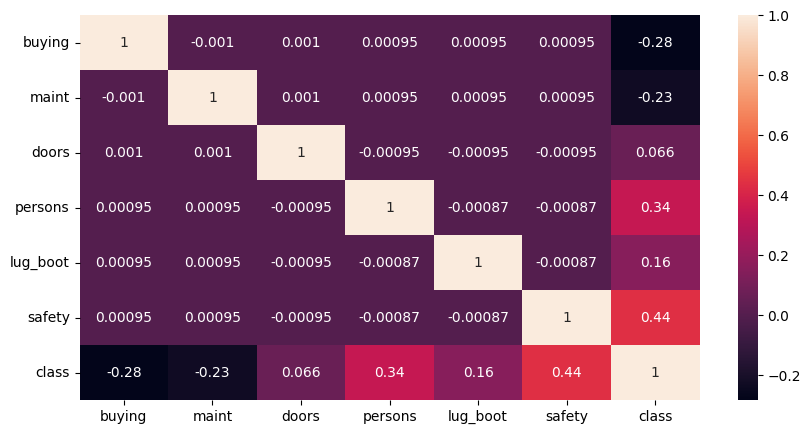

In [14]:
plt.figure(figsize=(10,5))
sns.heatmap(data.corr(),annot=True)
plt.show()

In [15]:
x = data.drop("class",axis=1)
y = data["class"]
x_train , x_test , y_train , y_test = train_test_split(
    x , y , test_size=0.2 , random_state=42
)
x_train.shape , x_test.shape , y_train.shape , y_test.shape

((1381, 6), (346, 6), (1381,), (346,))

In [16]:
model_tree = tree.DecisionTreeClassifier()
model_tree.fit(x_train,y_train)
y_pred_tree = model_tree.predict(x_test)
metrics.accuracy_score(y_test , y_pred_tree)*100

96.53179190751445

In [17]:
data.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

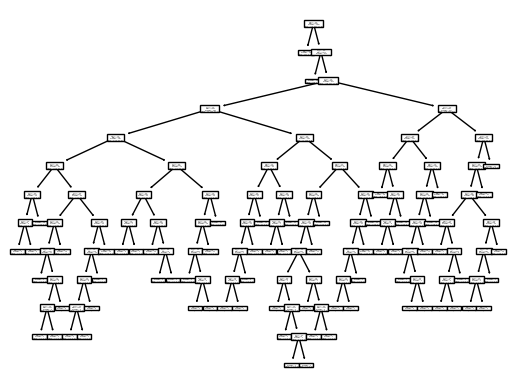

In [18]:
tree.plot_tree(model_tree)
plt.show()

In [19]:
model_log = linear_model.LogisticRegression()
model_log.fit(x_train,y_train)
y_pred_log = model_log.predict(x_test)
metrics.accuracy_score(y_test , y_pred_log)*100

83.23699421965318

In [20]:
model_forest = ensemble.RandomForestClassifier()
model_forest.fit(x_train,y_train)
y_pred_forest = model_forest.predict(x_test)
metrics.accuracy_score(y_test , y_pred_forest)*100

97.39884393063583